# ML Zoomcamp 2026 — Homework 4: Evaluation Metrics for Classification

Dataset: 2026 lead-scoring release. Target: `converted` (did the lead sign up?).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

DATA_URL = ('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/'
            'main/cohorts/2026/data/course_lead_scoring_2026.csv')
path = 'course_lead_scoring_2026.csv' if os.path.exists('course_lead_scoring_2026.csv') else DATA_URL
df = pd.read_csv(path)
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## Data preparation
Missing values: categorical → `'NA'`, numerical → `0.0`.

In [2]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [3]:
target = 'converted'
categorical = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
numerical = [c for c in df.columns if c not in categorical and c != target]

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

print('categorical:', categorical)
print('numerical:  ', numerical)
df.isnull().sum().sum()

categorical: ['lead_source', 'industry', 'employment_status', 'location']
numerical:   ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


np.int64(0)

Split 60/20/20 with the exact calls from the homework.

In [4]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train[target].values
y_val = df_val[target].values

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

## Q1. ROC AUC feature importance
Use each numerical feature on its own as a score. If AUC < 0.5 the feature is negatively correlated with the target, so we flip its sign.

In [5]:
q1 = {}
for c in numerical:
    auc = roc_auc_score(y_train, df_train[c])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])
    q1[c] = auc

pd.Series(q1).sort_values(ascending=False).round(4)

lead_score                  0.7882
interaction_count           0.7649
number_of_courses_viewed    0.7230
annual_income               0.6082
dtype: float64

## Q2. Train the model
One-hot encode with `DictVectorizer`, then logistic regression.

In [6]:
features = categorical + numerical

def train(df_, y_, C=1.0):
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(df_[features].to_dict(orient='records'))
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y_)
    return dv, model

def predict(df_, dv, model):
    X = dv.transform(df_[features].to_dict(orient='records'))
    return model.predict_proba(X)[:, 1]

dv, model = train(df_train, y_train)
y_pred = predict(df_val, dv, model)
round(roc_auc_score(y_val, y_pred), 3)

0.732

## Q3. Precision and recall
Thresholds 0.00 → 1.00, step 0.01. Find where the curves cross (smallest |P − R|, ignoring thresholds where both are 0).

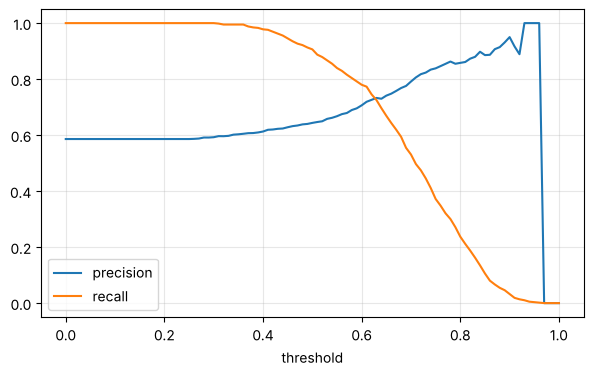

,threshold,precision,recall,diff
63,0.63,0.732759,0.725256,0.007503
62,0.62,0.725914,0.745734,0.019820
64,0.64,0.729875,0.696246,0.033629


In [7]:
thresholds = np.round(np.arange(0.0, 1.01, 0.01), 2)
rows = []
for t in thresholds:
    pred = y_pred >= t
    tp = ((pred == 1) & (y_val == 1)).sum()
    fp = ((pred == 1) & (y_val == 0)).sum()
    fn = ((pred == 0) & (y_val == 1)).sum()
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    rows.append((t, p, r))

df_pr = pd.DataFrame(rows, columns=['threshold', 'precision', 'recall'])

plt.figure(figsize=(7, 4))
plt.plot(df_pr.threshold, df_pr.precision, label='precision')
plt.plot(df_pr.threshold, df_pr.recall, label='recall')
plt.xlabel('threshold'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

valid = df_pr[~((df_pr.precision == 0) & (df_pr.recall == 0))].copy()
valid['diff'] = (valid.precision - valid.recall).abs()
valid.sort_values('diff').head(3)

## Q4. F1 score
$F_1 = 2 \cdot \frac{P \cdot R}{P + R}$

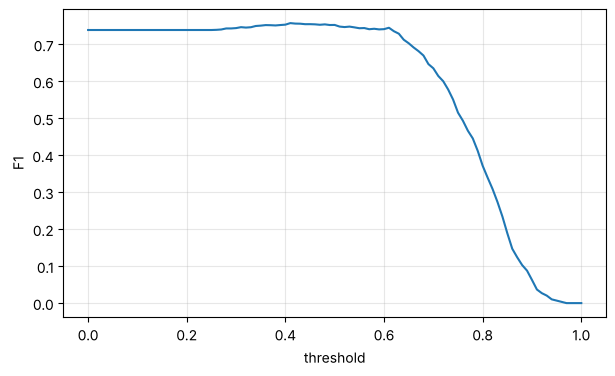

,threshold,precision,recall,f1
41,0.41,0.619048,0.976109,0.757616
42,0.42,0.620087,0.969283,0.756325
43,0.43,0.622517,0.962457,0.756032


In [8]:
df_pr['f1'] = np.where(
    (df_pr.precision + df_pr.recall) > 0,
    2 * df_pr.precision * df_pr.recall / (df_pr.precision + df_pr.recall),
    0.0,
)

plt.figure(figsize=(7, 4))
plt.plot(df_pr.threshold, df_pr.f1)
plt.xlabel('threshold'); plt.ylabel('F1'); plt.grid(alpha=0.3)
plt.show()

df_pr.sort_values('f1', ascending=False).head(3)

## Q5. 5-Fold CV
Train on 4 folds of `df_full_train`, score AUC on the 5th.

In [9]:
def cv_scores(C=1.0):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]
        dv_, model_ = train(df_tr, df_tr[target].values, C=C)
        scores.append(roc_auc_score(df_va[target].values, predict(df_va, dv_, model_)))
    return np.array(scores)

scores = cv_scores(C=1.0)
print('fold AUCs:', scores.round(3))
print('mean = %.3f  std = %.3f' % (scores.mean(), scores.std()))

fold AUCs: [0.731 0.73  0.736 0.741 0.721]
mean = 0.732  std = 0.007


## Q6. Hyperparameter tuning
Mean and std of CV AUC for each `C`. Ties → lower std → smaller `C`.

In [10]:
results = []
for C in [0.000001, 0.001, 1]:
    s = cv_scores(C=C)
    results.append((C, round(s.mean(), 3), round(s.std(), 3)))

df_c = pd.DataFrame(results, columns=['C', 'mean_auc', 'std_auc'])
df_c.sort_values(['mean_auc', 'std_auc', 'C'], ascending=[False, True, True])

,C,mean_auc,std_auc
1,0.001000,0.749,0.010
2,1.000000,0.732,0.007
0,0.000001,0.617,0.019
